# Artifitial neural network 

## Example 1: California housing prices

In [1]:
# install and import tensor flow
import tensorflow

In [2]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input

In [4]:
data = fetch_california_housing()

X, y =data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [5]:
# Scaler
Scaler = StandardScaler()
X_train = Scaler.fit_transform(X_train)
X_test = Scaler.fit_transform(X_test)

In [6]:
# convert to df
df = pd.DataFrame(X_train,columns=data.feature_names)
df['target'] = y_train
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,-0.326196,0.348490,-0.174916,-0.208365,0.768276,0.051376,-1.372811,1.272587,1.030
1,-0.035843,1.618118,-0.402835,-0.128530,-0.098901,-0.117362,-0.876696,0.709162,3.821
2,0.144701,-1.952710,0.088216,-0.257538,-0.449818,-0.032280,-0.460146,-0.447603,1.726
3,-1.017864,0.586545,-0.600015,-0.145156,-0.007434,0.077507,-1.382172,1.232698,0.934
4,-0.171488,1.142008,0.349007,0.086624,-0.485877,-0.068832,0.532084,-0.108551,0.965


In [7]:
#sns.pairplot(df, hue='target')

In [8]:
model = Sequential([
    Input(shape= (X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dense(1)
])

In [9]:
model.compile(optimizer='adam', loss = 'mse',metrics=['mae'])

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             576 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,697 (116.00 KB)

 Trainable params: 29,697 (116.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(X_train, y_train, epochs=50,batch_size=32,validation_split=0.2)

Epoch 1/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 1.1903 - mae: 0.7634 - val_loss: 0.4198 - val_mae: 0.4752
Epoch 2/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4108 - mae: 0.4630 - val_loss: 0.3816 - val_mae: 0.4360
Epoch 3/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3560 - mae: 0.4279 - val_loss: 0.4008 - val_mae: 0.4368
Epoch 4/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3609 - mae: 0.4252 - val_loss: 0.3604 - val_mae: 0.4418
Epoch 5/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3532 - mae: 0.4211 - val_loss: 0.3391 - val_mae: 0.3996
Epoch 6/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3402 - mae: 0.4069 - val_loss: 0.3661 - val_mae: 0.4057
Epoch 7/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3223 - mae: 0.4000 - val_loss: 0.3393 - val_mae: 0.3998
Epoch 8/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3162 - mae: 0.3911 - val_loss: 0.3278 - val_mae: 0.4073
Epoch 9/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - lo

In [12]:
y_pred = model.predict(X_test)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [13]:
r2_score(y_test,y_pred)

-3.6953827458657873

In [14]:
#model.evaluate(y_test,y_pred)

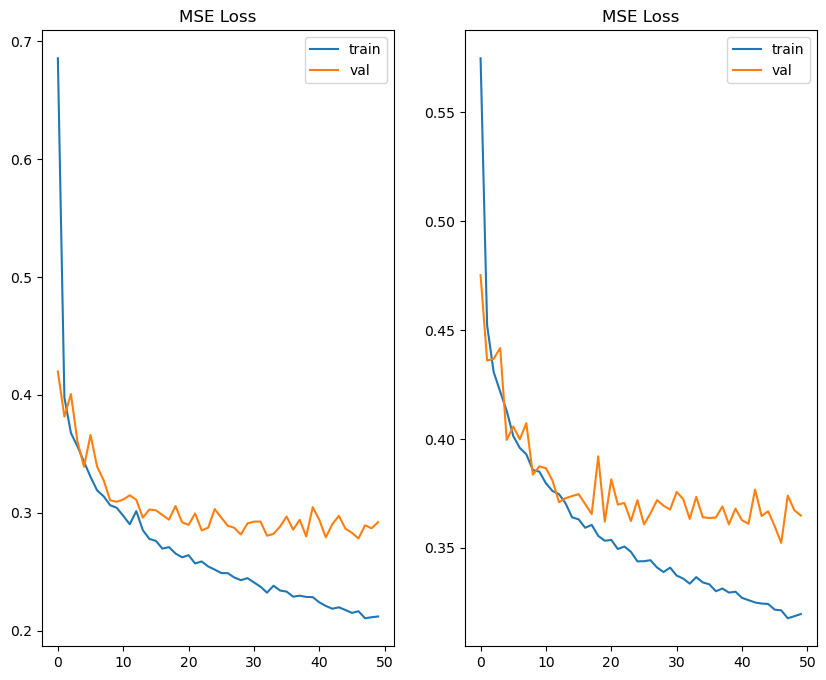

In [15]:
plt.figure(figsize=(10,8))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],label = 'train')
plt.plot(history.history['val_loss'],label = 'val')
plt.title("MSE Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'],label = 'train')
plt.plot(history.history['val_mae'],label = 'val')
plt.title("MSE Loss")
plt.legend()

## Example 2: Bank defaulter customer classifier

In [16]:
df = pd.read_csv('bank-additional-full.csv',sep=';',header=0)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [17]:
df.shape

(41188, 21)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [19]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [20]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [21]:
df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [22]:
df.select_dtypes('object')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,no
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,no
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent,no
...,...,...,...,...,...,...,...,...,...,...,...
41183,retired,married,professional.course,no,yes,no,cellular,nov,fri,nonexistent,yes
41184,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,nonexistent,no
41185,retired,married,university.degree,no,yes,no,cellular,nov,fri,nonexistent,no
41186,technician,married,professional.course,no,no,no,cellular,nov,fri,nonexistent,yes


In [23]:
df['marital'].value_counts()

marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

In [24]:
df['y'] = df['y'].map({'no':0,'yes':1})

In [25]:
df['y']

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: y, Length: 41188, dtype: int64

In [26]:
# separte features and targets
x = df.drop('y',axis=1)
y = df['y']

# Label encode catagory
cat_cols = x.select_dtypes(include='object').columns

In [27]:
cat_cols

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')

In [28]:
for col in cat_cols:
    x[col] = LabelEncoder().fit_transform(x[col])

In [29]:
x

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,3,1,0,0,0,0,1,6,1,261,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0
1,57,7,1,3,1,0,0,1,6,1,149,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0
2,37,7,1,3,0,2,0,1,6,1,226,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0
3,40,0,1,1,0,0,0,1,6,1,151,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0
4,56,7,1,3,0,0,2,1,6,1,307,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,5,1,5,0,2,0,0,7,0,334,1,999,0,1,-1.1,94.767,-50.8,1.028,4963.6
41184,46,1,1,5,0,0,0,0,7,0,383,1,999,0,1,-1.1,94.767,-50.8,1.028,4963.6
41185,56,5,1,6,0,2,0,0,7,0,189,2,999,0,1,-1.1,94.767,-50.8,1.028,4963.6
41186,44,9,1,5,0,0,0,0,7,0,442,1,999,0,1,-1.1,94.767,-50.8,1.028,4963.6


In [30]:
x.shape

(41188, 20)

In [31]:
y.shape

(41188,)

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)

In [33]:
# scaling
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

In [34]:
x_train.shape[1]

20

In [35]:
Model = Sequential([
    Input(shape = (x_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [36]:
Model.compile(optimizer='adam', loss = 'mse',metrics=['mae'])

In [37]:
Model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 64)                  │           1,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
history = Model.fit(x_train, y_train, epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.0956 - mae: 0.2028 - val_loss: 0.0624 - val_mae: 0.1323
Epoch 2/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0650 - mae: 0.1310 - val_loss: 0.0615 - val_mae: 0.1249
Epoch 3/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0641 - mae: 0.1258 - val_loss: 0.0609 - val_mae: 0.1240
Epoch 4/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0639 - mae: 0.1249 - val_loss: 0.0604 - val_mae: 0.1186
Epoch 5/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0616 - mae: 0.1206 - val_loss: 0.0611 - val_mae: 0.1149
Epoch 6/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0599 - mae: 0.1162 - val_loss: 0.0602 - val_mae: 0.1183
Epoch 7/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0620 - mae: 0.1201 - val_loss: 0.0600 - val_mae: 0.1183
Epoch 8/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0576 - mae: 0.1131 - val_loss: 0.0598 - val_mae: 0.1182
Epoch 9/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - lo

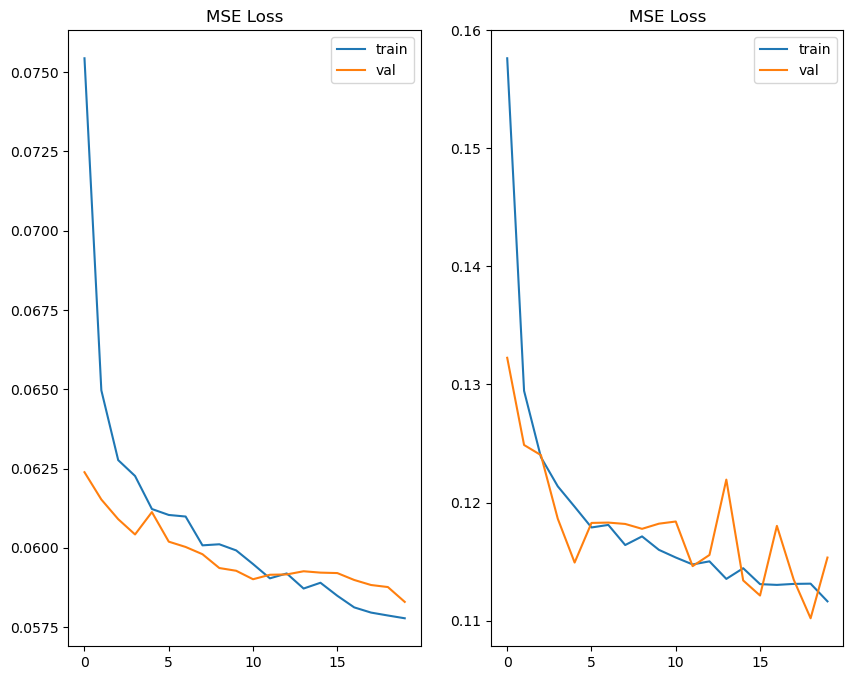

In [39]:
plt.figure(figsize=(10,8))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],label = 'train')
plt.plot(history.history['val_loss'],label = 'val')
plt.title("MSE Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'],label = 'train')
plt.plot(history.history['val_mae'],label = 'val')
plt.title("MSE Loss")
plt.legend()

In [40]:
y_pred = Model.predict(x_test)

258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [41]:
r2_score(y_test,y_pred)

0.4362398386001587

In [42]:
Model.evaluate(x_test, y_test)

258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0561 - mae: 0.1117


[0.0563528947532177, 0.11218885332345963]

In [43]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_labels = (y_pred > 0.5).astype(int)

print(confusion_matrix(y_test, y_pred_labels))
print(classification_report(y_test, y_pred_labels))


[[7114  196]
 [ 492  436]]
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      7310
           1       0.69      0.47      0.56       928

    accuracy                           0.92      8238
   macro avg       0.81      0.72      0.76      8238
weighted avg       0.91      0.92      0.91      8238



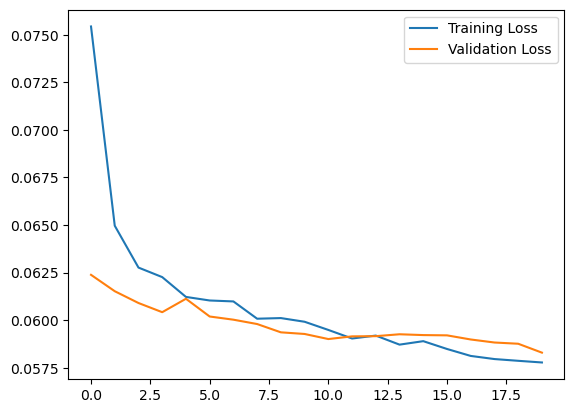

In [44]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()